# 3D-03 — Gaussian Splats : la transition du volume continu au nuage explicite

[← Critique de NeRF (3D-02)](3D-02-NeRF-Critic.ipynb) | [← Série GenAI/3D](README.md)

> **Ce que fait ce notebook** : [3D-02](3D-02-NeRF-Critic.ipynb) a mesuré cinq limitations de NeRF et montré que quatre se corrigent en **changeant de représentation**. Ce carnet construit cette représentation — les **3D Gaussian Splats** (Kerbl et al., SIGGRAPH 2023) — morceau par morceau : l'anatomie d'un splat (position, covariance, couleur, opacité), sa projection 2D, le compositing sans rayon. La même scène « Saturne » que [3D-01](3D-01-NeRF-From-Scratch.ipynb) est ensuite représentée **dans les deux mondes** : rendu volumique continu d'un côté, nuage de gaussiennes optimisées de l'autre — sans moteur CUDA externe, pour voir la mécanique à l'œil nu (**3D-04** branchera le vrai moteur `gsplat`).

**Prérequis** : [3D-01](3D-01-NeRF-From-Scratch.ipynb) (rendu volumique, compositing alpha) et [3D-02](3D-02-NeRF-Critic.ipynb) (limitations, en particulier la n°5 : le coût du rendu par rayon).

*Note d'exécution* : déterministe (seed 42) ; ~6-8 min sur CPU, aucun GPU requis — les 550 itérations de la section 5 dominent ; le moteur CUDA `gsplat` est précisément le sujet du carnet suivant (**3D-04**).

In [1]:
import os, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Outils charges — torch {torch.__version__}. Execution CPU assumee : le moteur CUDA gsplat arrive en 3D-04.")

Outils charges — torch 2.8.0+cu126. Execution CPU assumee : le moteur CUDA gsplat arrive en 3D-04.


## 1. Deux représentations pour une même scène

NeRF encode la scène dans une **fonction continue** $f_\theta(\mathbf{x}, \mathbf{d}) \mapsto (\sigma, \mathbf{c})$, évaluée des millions de fois par image le long des rayons (c'est la limitation n°5 de [3D-02](3D-02-NeRF-Critic.ipynb)). Le geste de 3D Gaussian Splatting (Kerbl et al., *3D Gaussian Splatting for Real-Time Radiance Field Synthesis*, SIGGRAPH 2023) est de changer de catégorie : la scène devient un **ensemble explicite de $M$ primitives 3D** — des gaussiennes anisotropes, les *splats* — rendues par **rasterization** (projection, tri, mélange), pas par échantillonnage.

| | NeRF (implicite) | 3DGS (explicite) |
|---|---|---|
| La scène est... | les poids $\theta$ d'un MLP | une liste de $M$ gaussiennes : positions, covariances, couleurs, opacités |
| Rendu | ray-marching, $N$ évaluations du réseau par rayon | projection des splats sur l'image, tri par profondeur, mélange alpha |
| Coût par pixel | $N \times$ coût du MLP (des centaines d'évaluations) | nombre de splats couvrant le pixel (souvent une dizaine) |
| Inspection/édition | difficile (tout est dans les poids) | directe : chaque splat a une position, une orientation, une couleur |
| Entraînement | optimiser $\theta$ | optimiser **les attributs des splats eux-mêmes** (même autograd, autre cible) |

Le reste du champ de vision par ordinateur ne part pas de zéro : les splats réels s'initialisent depuis un nuage de points SfM (COLMAP — la limitation n°3 de 3D-02 reste vraie : il faut des poses). Ce carnet travaille sur la même scène jouet analytique que 3D-01 pour garder le contrôle de la vérité terrain.

Reconstruisons d'abord la scène « Saturne » et son rendu volumique — c'est le côté « continu » du comparatif, et la cible que les splats devront reproduire.

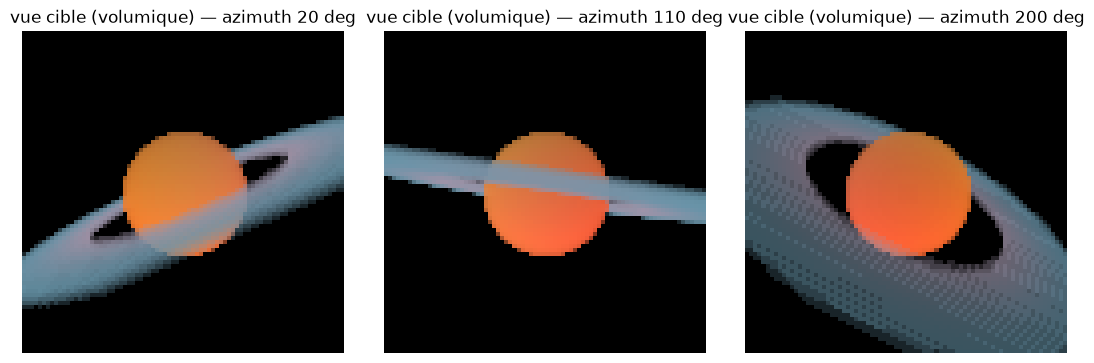

In [2]:
# Scene « Saturne » (reprise compacte de 3D-01) : sphere + anneau incline, densites analytiques.
INCLINAISON = math.radians(25.0)

def densite_analytique(p):
    # p : (..., 3). Renvoie la densite sigma (..., 1) : sphere pleine + anneau plat incline.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2)
    # Sphere pleine de rayon 0.55 centree a l'origine.
    d_sphere = torch.where(x**2 + y**2 + z**2 < 0.55**2, 8.0 * torch.ones_like(x), torch.zeros_like(x))
    # Anneau : plan z=0 tourne de INCLINAISON autour de x, rayons 0.85..1.55, epaisseur 0.05.
    zp = z * math.cos(INCLINAISON) - y * math.sin(INCLINAISON)
    yp = z * math.sin(INCLINAISON) + y * math.cos(INCLINAISON)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55) & (zp.abs() < 0.05)
    d_anneau = torch.where(dans_anneau, 6.0 * torch.ones_like(x), torch.zeros_like(x))
    return torch.clamp(d_sphere + d_anneau, max=10.0)

def couleur_analytique(p):
    # Couleur diffuse simple : coeur chaud, anneau gris-bleute.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r = torch.sqrt(x**2 + y**2 + z**2 + 1e-9)
    r_axial = torch.sqrt(x**2 + y**2 + 1e-9)
    c_sphere = torch.stack([0.92 - 0.35 * z, 0.45 + 0.15 * x, 0.22 + 0.10 * y], dim=-1)
    c_anneau = torch.stack([0.55 + 0.15 * torch.sin(3 * r_axial), torch.full_like(x, 0.58), torch.full_like(x, 0.66)], dim=-1)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55)
    return torch.where(dans_anneau.unsqueeze(-1), c_anneau, c_sphere).clamp(0, 1)

def pose_spherique(theta, r=3.2, phi=math.radians(70)):
    # Pose c2w (look-at origine) sur l'orbite, meme esprit que 3D-01.
    ct, st, cp, sp = math.cos(theta), math.sin(theta), math.cos(phi), math.sin(phi)
    c2w = np.array([
        [-st, -ct * cp, ct * sp, r * ct * sp],
        [ ct, -st * cp, st * sp, r * st * sp],
        [0.0,       sp,      cp,      r * cp],
        [0.0,      0.0,     0.0,        1.0],
    ], dtype=np.float32)
    return c2w

def rendu_volumique_analytique(theta, H=80, W=80, N=64, near=1.8, far=4.8, focal=90.0):
    # Ray-marching direct de la densite analytique (le "continu", sans reseau) : c'est la cible.
    c2w = torch.tensor(pose_spherique(theta))
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    dirs = torch.stack([(ii - W / 2) / focal, -(jj - H / 2) / focal, -torch.ones_like(ii)], dim=-1)
    rays_d = dirs @ c2w[:3, :3].T
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    ts = near + (far - near) * torch.linspace(0, 1, N)
    pts = rays_o.unsqueeze(-2) + rays_d.unsqueeze(-2) * ts.view(1, 1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_analytique(pts)
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    w = alpha * torch.cumprod(torch.cat([torch.ones_like(alpha[..., :1]), 1 - alpha + 1e-10], dim=-1)[..., :-1], dim=-1)
    img = torch.sum(w.unsqueeze(-1) * rgb, dim=-2)
    return img.clamp(0, 1)

ANGLES_CIBLES = [math.radians(a) for a in (20, 110, 200)]
vues_cibles = torch.stack([rendu_volumique_analytique(t) for t in ANGLES_CIBLES])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, img, a in zip(axes, vues_cibles, (20, 110, 200)):
    ax.imshow(img.numpy()); ax.set_title(f"vue cible (volumique) — azimuth {a} deg"); ax.axis('off')
plt.tight_layout(); plt.show()

### Lecture du résultat

Trois vues de référence rendues par ray-marching **de la densité analytique elle-même** : c'est la vérité terrain continue, exactement ce que le NeRF de 3D-01 s'épuisait à approximer en évaluant un MLP. La question de ce carnet : **quel niveau de fidélité atteint un nuage de $M$ gaussiennes, optimisées sans réseau du tout ?** Et que gagne-t-on en échange ?

## 2. L'anatomie d'un splat

Un splat est une gaussienne 3D anisotrope dotée d'attributs **optimisables individuellement** :

| Attribut | Paramètres | Rôle |
|---|---|---|
| Position $\boldsymbol{\mu} \in \mathbb{R}^3$ | 3 | où la primitive vit |
| Covariance $\boldsymbol{\Sigma} = \mathbf{R}\mathbf{S}\mathbf{S}^\top\mathbf{R}^\top$ | 4 (quaternion) + 3 (échelles) | forme et orientation — ellipsoïde, pas sphère |
| Couleur | $3 \times (\ell+1)^2$ coefficients SH (degré $\ell$) | radiance vue-dépendante (ici degré 0 : RGB constant) |
| Opacité $o$ | 1 (logistique) | poids dans le mélange |

Sa densité en tout point : $\;d(\mathbf{x}) = \exp\!\left(-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{x}-\boldsymbol{\mu})\right)$ — et chaque splat porte sa **propre** couleur, contrairement au NeRF qui la fait dépendre du point et de la direction via le réseau.

La couleur mérite un mot : le papier 3DGS encode la radiance en **harmoniques sphériques** (SH) — une base de fonctions sur la sphère de directions, degré $\ell = 0$ (constant, 1 coefficient) à $\ell = 3$ (16 coefficients) par canal. Le degré 0 donne la couleur moyenne ; les degrés supérieurs ajoutent la variation avec l'angle de vue (réflexions spéculaires par exemple). Ce carnet optimise au degré 0 (RGB constant par splat) ; **3D-04** montrera le pipeline SH complet.

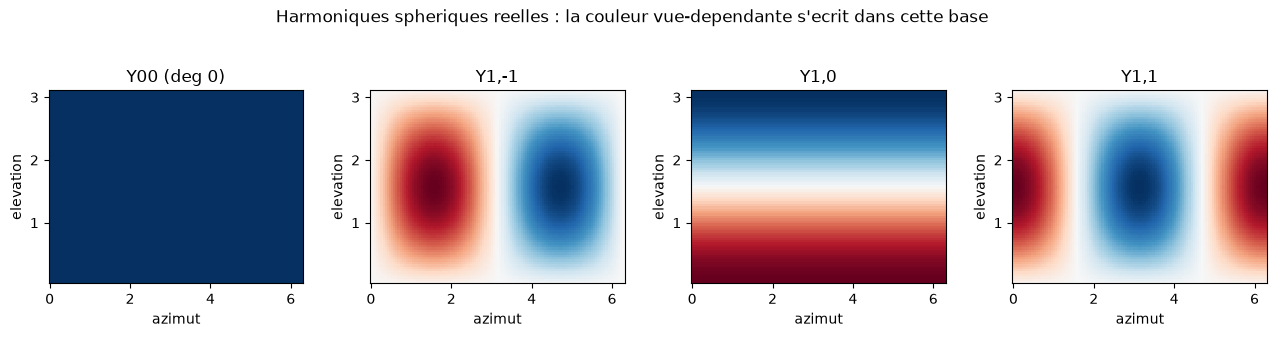

In [3]:
# Les harmoniques spheriques reelles de degre 0 et 1, tracees sur le disque des directions.
def sh_reelles(theta, phi):
    # Degre 0 : Y00 = 0.5/sqrt(pi). Degre 1 : Y1-1 ~ sin(theta)sin(phi), Y10 ~ cos(theta), Y11 ~ sin(theta)cos(phi).
    Y00 = 0.5 / math.sqrt(math.pi) * torch.ones_like(theta)
    Y1m1 = math.sqrt(3 / (4 * math.pi)) * torch.sin(theta) * torch.sin(phi)
    Y10 = math.sqrt(3 / (4 * math.pi)) * torch.cos(theta)
    Y11 = math.sqrt(3 / (4 * math.pi)) * torch.sin(theta) * torch.cos(phi)
    return {"Y00 (deg 0)": Y00, "Y1,-1": Y1m1, "Y1,0": Y10, "Y1,1": Y11}

phi_g = torch.linspace(0, 2 * math.pi, 120)
theta_g = torch.linspace(0.05, math.pi - 0.05, 80)
PHI, THETA = torch.meshgrid(phi_g, theta_g, indexing='xy')
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (nom, Z) in zip(axes, sh_reelles(THETA, PHI).items()):
    ax.pcolormesh(PHI.numpy(), THETA.numpy(), Z.numpy(), cmap='RdBu_r', shading='auto')
    ax.set_title(nom); ax.set_xlabel('azimut'); ax.set_ylabel('elevation')
plt.suptitle("Harmoniques spheriques reelles : la couleur vue-dependante s'ecrit dans cette base", y=1.04)
plt.tight_layout(); plt.show()

### Lecture

Les SH de degré 0 sont constantes (la couleur moyenne du splat) ; celles de degré 1 varient linéairement avec la direction — un splat peut ainsi paraître plus clair vu de gauche que de droite. La base est **orthogonale** : chaque coefficient règle une fréquence angulaire indépendante, exactement comme l'encodage positionnel de NeRF règle des fréquences spatiales (le pont Fourier features de [3.4d](../../ML/DataScienceWithAgents/03-DeepLearning/3.4d-Fourier-Features-Biais-Spectral-Python.ipynb)).

## 3. La covariance paramétrée : $\boldsymbol{\Sigma} = \mathbf{R}\mathbf{S}\mathbf{S}^\top\mathbf{R}^\top$

Trois façons de stocker une covariance : les 6 coefficients de la matrice symétrique, ses axes/valeurs propres, ou **la décomposition rotation-échelle**. Le papier 3DGS choisit la troisième — un quaternion unitaire $\mathbf{q}$ (4 nombres, rotation 3 ddl) et une échelle $\mathbf{s} \in \mathbb{R}^3$ — pour une raison d'optimisation : la décomposition **garantit par construction une matrice définie positive**, ce qu'aucune des deux autres représentations n'assure pendant une descente de gradient. Une covariance non définie positive n'est plus une gaussienne : l'optimisation directe des 6 coefficients diverge, la décomposition ne peut pas.

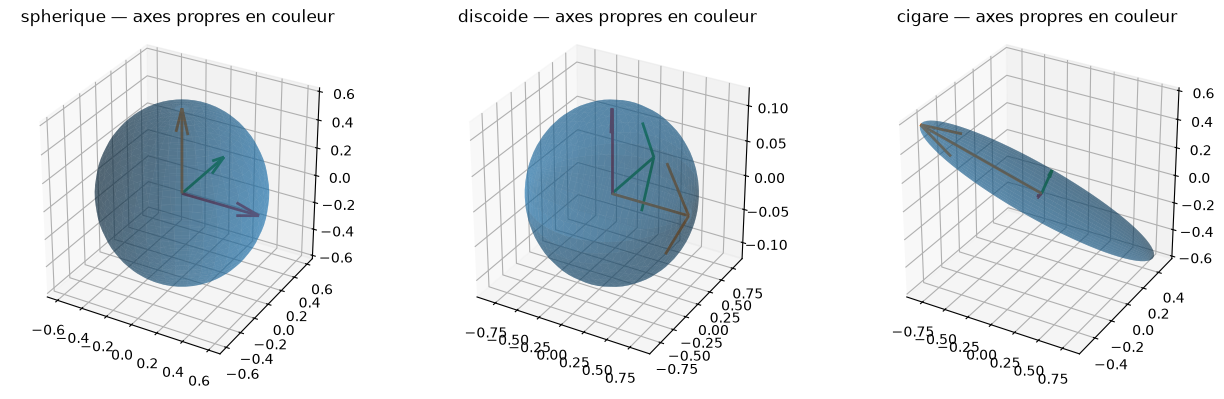

In [4]:
def quat_vers_matrice(q):
    # Quaternion unitaire (w, x, y, z) -> matrice de rotation 3x3 (formule du papier 3DGS, annexe A).
    w, x, y, z = q.unbind(-1)
    return torch.stack([
        1 - 2 * (y**2 + z**2), 2 * (x * y - w * z),     2 * (x * z + w * y),
        2 * (x * y + w * z),     1 - 2 * (x**2 + z**2), 2 * (y * z - w * x),
        2 * (x * z - w * y),     2 * (y * z + w * x),   1 - 2 * (x**2 + y**2),
    ], dim=-1).reshape(*q.shape[:-1], 3, 3)

def covariance_3d(s, q):
    # Sigma = R diag(s)^2 R^T  (l'echelle entre au carre).
    R = quat_vers_matrice(q)
    S = torch.diag_embed(s**2)
    return R @ S @ R.transpose(-1, -2)

# Trois splats de meme volume, formes differentes : sphere, disque, cigare.
formes = {
    "spherique": (torch.tensor([0.30, 0.30, 0.30]), torch.tensor([1.0, 0, 0, 0])),
    "discoide" : (torch.tensor([0.42, 0.42, 0.06]), torch.tensor([1.0, 0, 0, 0])),
    "cigare"   : (torch.tensor([0.55, 0.08, 0.08]), torch.tensor([0.9, 0.1, 0.3, 0.2])),
}
fig = plt.figure(figsize=(13, 4))
for k, (nom, (s, q)) in enumerate(formes.items()):
    Sigma = covariance_3d(s, q / q.norm())
    val, vec = torch.linalg.eigh(Sigma)
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    u, v = torch.meshgrid(torch.linspace(0, 2 * math.pi, 40), torch.linspace(0, math.pi, 40), indexing='xy')
    sphere = torch.stack([torch.cos(u) * torch.sin(v), torch.sin(u) * torch.sin(v), torch.cos(v)], dim=-1).reshape(-1, 3)
    ell = (2.0 * (sphere @ torch.diag(torch.sqrt(val)) @ vec.T)).reshape(40, 40, 3).permute(2, 0, 1).numpy()
    ax.plot_surface(ell[0], ell[1], ell[2], alpha=0.45, color='tab:blue', edgecolor='none')
    for j in range(3):
        ax.quiver(0, 0, 0, *(vec[:, j] * torch.sqrt(val[j]) * 2).numpy(), color=['tab:red', 'tab:green', 'tab:orange'][j], lw=2)
    ax.set_title(f"{nom} — axes propres en couleur"); ax.set_box_aspect([1, 1, 1])
plt.tight_layout(); plt.show()

### Lecture

Une même quantité de « matière » (même déterminant), trois formes : le splat **s'adapte à la géométrie locale** — une surface se représente par des disques fins (l'anneau de Saturne), un filament par des cigares, une zone diffuse par des sphères. C'est l'argument d'efficacité central : là où le voxels et les points échantillonnent uniformément, la covariance concentre la capacité **là où la scène en a besoin**. Les axes propres (rouge, vert, orange) sont exactement ce que le rasterizer projettera à l'écran.

## 4. Le rendu splat : projeter, trier, mélanger — sans rayon

Le rendu NeRF demande, pour chaque pixel, de marcher le long du rayon et d'évaluer le réseau $N$ fois. Le rendu splat inverse la boucle : **chaque splat se projette lui-même** sur l'image.

1. **Projeter** : le centre $\boldsymbol{\mu}$ suit la caméra $\mathbf{W}$ ; la covariance subit l'approximation affine locale $\;\boldsymbol{\Sigma}' = \mathbf{J}\mathbf{W}\,\boldsymbol{\Sigma}\,(\mathbf{J}\mathbf{W})^\top$, où $\mathbf{J}$ est la Jacobienne de la projection perspective — une gaussienne 3D reste une gaussienne (2D) à l'écran.
2. **Trier** : les splats couvrant un pixel sont ordonnés par profondeur (une fois par image — c'est le travail du *tile-based rasterizer* de `gsplat`, que **3D-04** profile).
3. **Mélanger** : le même compositing front-to-back que NeRF, mais fourni par les splats :
$$C = \sum_{i \in \text{triés}} c_i\, \alpha_i \prod_{j<i}(1-\alpha_j), \qquad \alpha_i(\mathbf{u}) = o_i \exp\!\left(-\tfrac{1}{2}(\mathbf{u}-\boldsymbol{\mu}_i')^\top \boldsymbol{\Sigma}_i'^{-1} (\mathbf{u}-\boldsymbol{\mu}_i')\right)$$

La ressemblance avec l'équation du rendu volumique de 3D01 n'est pas une coïncidence : c'est **la même famille de mélange alpha**, ce qui change est *qui* fournit $\alpha$ (le réseau échantillonné le long du rayon vs le splat projeté) et le coût (des centaines d'évaluations vs une poignée par pixel).

In [5]:
class RenduSplats(torch.nn.Module):
    # Rasterizer splats minimal, differentiable, sans CUDA : projeter -> evaluer alpha par pixel -> trier -> melanger.
    def __init__(self, H=80, W=80, focal=90.0):
        super().__init__()
        self.H, self.W, self.focal = H, W, focal
        ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
        # Grille en COORDONNEES ECRAN (pixels, origine au centre) : u, v, Jacobienne et cov2d
        # vivent toutes en pixels -- le pipeline splat est homogene. Ne pas normaliser par la
        # focale ici : les directions de rayons de la section volumique sont focal-relatives,
        # melanger les deux echelles rend l'image vide (aucun splat ne touche la grille).
        self.register_buffer("pixels", torch.stack([ii - W / 2, -(jj - H / 2)], dim=-1).reshape(-1, 2))

    def forward(self, means3d, scales, quats, couleurs, logits_opa, theta, r=3.2, phi=math.radians(70)):
        c2w = torch.tensor(pose_spherique(float(theta), r=r, phi=phi))
        cam_R, cam_t = c2w[:3, :3], c2w[:3, -1]
        vue = (means3d - cam_t) @ cam_R            # points dans le repere camera
        depth = -vue[..., 2]                        # profondeur le long de l'axe optique
        u = self.focal * (vue[..., 0] / depth)      # projection perspective
        v = self.focal * (vue[..., 1] / depth)
        # Jacobienne affine de la projection, evaluee par splat.
        z = depth.clamp(min=0.1)
        J = torch.zeros(means3d.shape[0], 2, 3)
        J[:, 0, 0] = self.focal / z; J[:, 1, 1] = self.focal / z
        J[:, 0, 2] = -self.focal * vue[:, 0] / z**2
        J[:, 1, 2] = -self.focal * vue[:, 1] / z**2
        Sigma = covariance_3d(scales, quats)
        JW = J @ cam_R
        cov2d = JW @ Sigma @ JW.transpose(-1, -2)
        cov2d = cov2d + 1e-4 * torch.eye(2)         # anti-aliasing minimal (filtre ecran)
        inv = torch.linalg.inv(cov2d)
        du = self.pixels.unsqueeze(0) - torch.stack([u, v], dim=-1).unsqueeze(1)
        maha = torch.einsum('npd,nde,npe->np', du, inv, du)
        alpha = torch.sigmoid(logits_opa).unsqueeze(1) * torch.exp(-0.5 * maha)
        ordre = torch.argsort(depth.detach(), descending=True)   # tri detached : le gradient passe par les valeurs
        alpha, c = alpha[ordre], couleurs[ordre]
        T = torch.cumprod(torch.cat([torch.ones(1, alpha.shape[1]), (1 - alpha + 1e-9)], dim=0)[:-1], dim=0)
        contrib = alpha.unsqueeze(-1) * c.unsqueeze(1) * T.unsqueeze(-1)
        return (contrib.sum(0)).reshape(self.H, self.W, 3).clamp(0, 1), depth, alpha

renderer = RenduSplats()
print(f"Renderer pret : grille {renderer.H}x{renderer.W} = {renderer.H * renderer.W} pixels.")

Renderer pret : grille 80x80 = 6400 pixels.


### Lecture

Le rasterizer tient en une page : projection, Jacobienne, inverse 2×2, exponentielle, tri, produit cumulé. Deux choix méritent d'être nommés car ils reviennent dans tout pipeline splat : le **filtre écran** (`+ 1e-4` sur la diagonale — sans lui, un splat vu de loin rétrécit à rien, c'est l'anti-aliasing du papier) et le **tri détaché** (l'ordre vient de profondeurs sorties du graphe : les gradients traversent les valeurs, pas la permutation — le choix standard des implémentations simples).

## 5. La même scène dans les deux représentations

L'expérience centrale : initialiser $M$ splats **en échantillonnant la densité analytique** (le rôle que joue le nuage COLMAP dans le pipeline réel), puis optimiser positions, échelles, rotations, couleurs et opacités par Adam — contre les **vues volumiques** de la section 1. Aucun réseau : le gradient descend directement sur les attributs des primitives. C'est la définition exacte de l'entraînement 3DGS, à main nue.

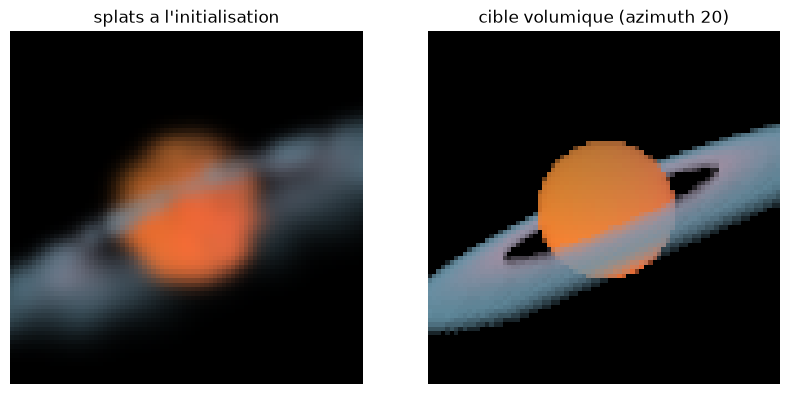

In [6]:
# Initialisation : M splats echantillonnes la ou la densite analytique vit (rejet uniforme).
M = 600
def echantillonner_densite(M, boite=1.8, batch=20000):
    gardes = []
    while sum(g.shape[0] for g in gardes) < M:
        p = (torch.rand(batch, 3) * 2 - 1) * boite
        d = densite_analytique(p)
        gardes.append(p[torch.rand(batch) < d / 10.0])
    return torch.cat(gardes)[:M]

means0 = echantillonner_densite(M)
scales0 = 0.08 + 0.02 * torch.rand(M, 3)
quats0 = torch.nn.functional.normalize(torch.tensor([1.0, 0, 0, 0]).expand(M, 4) + 0.01 * torch.randn(M, 4), dim=-1)
rgb0 = couleur_analytique(means0)
opa0 = -2.2 + 0.1 * torch.randn(M)  # logits : opacite initiale ~0.10 — nuage discret des le depart (cible lum ~0.15, init precedente 0.53 dominait le gradient)

means3d = torch.nn.Parameter(means0.clone())
log_scales = torch.nn.Parameter(torch.log(scales0.clone()))
quats = torch.nn.Parameter(quats0.clone())
couleurs = torch.nn.Parameter(rgb0.clone())
logits_opa = torch.nn.Parameter(opa0.clone())
params = [means3d, log_scales, quats, couleurs, logits_opa]

def splats_vers_attributs():
    # Quaternion re-normalise (contrainte unitaire) et echelles bornees en bas a 0.03 :
    # sans plancher, l'optimisation effondre les splats en points sous-pixel — le rendu
    # reste correct par superposition de centaines d'alphas faibles, mais la geometrie
    # (disques, cigares) disparait, et avec elle l'interet meme de la representation.
    return (means3d, log_scales.exp().clamp(min=0.03), torch.nn.functional.normalize(quats, dim=-1),
            couleurs.clamp(0, 1), logits_opa)

img_avant, _, _ = renderer(*splats_vers_attributs(), theta=ANGLES_CIBLES[0])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4))
axes[0].imshow(img_avant.detach().numpy()); axes[0].set_title("splats a l'initialisation"); axes[0].axis('off')
axes[1].imshow(vues_cibles[0].numpy()); axes[1].set_title("cible volumique (azimuth 20)"); axes[1].axis('off')
plt.tight_layout(); plt.show()

C:\Users\jsboi\AppData\Local\Temp\ipykernel_30116\4054984617.py:22: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:836.)
  historique.append((it, float(perte)))


Optimisation : 550 iterations en 951.4s — perte finale 0.0168 (L1 moyen par vue)


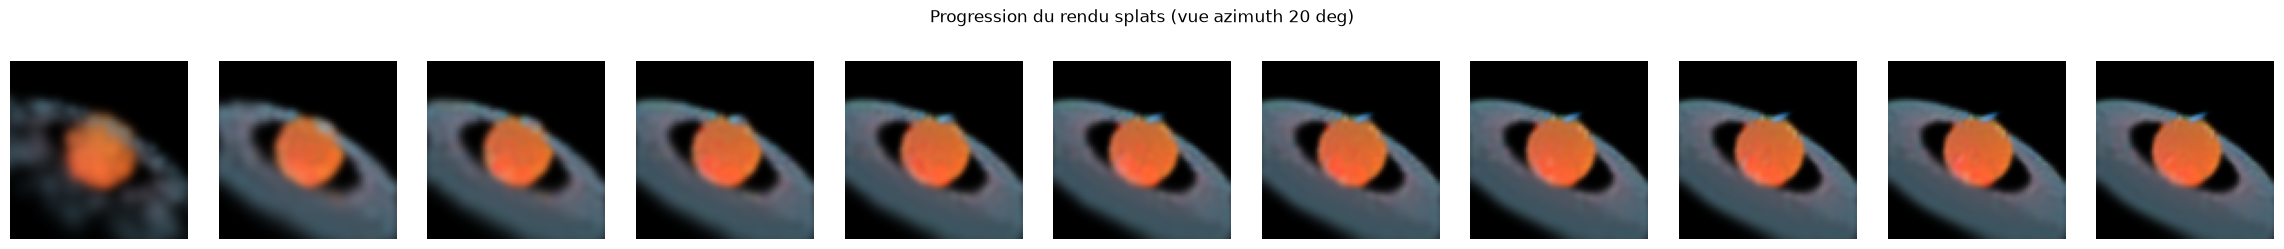

In [7]:
# Optimisation : Adam sur les attributs des splats, loss L1 contre les 3 vues volumiques cibles.
# LR différenciés par groupe d'attributs (le levier central que 3D-05 audite) : les positions
# bougent vite, les échelles lentement — un LR unique pousse les splats à rétrécir en points.
N_ITERS = 550
opt = torch.optim.Adam([
    {'params': [means3d], 'lr': 1e-2},
    {'params': [log_scales], 'lr': 2e-3},
    {'params': [quats], 'lr': 1e-3},
    {'params': [couleurs], 'lr': 5e-3},
    {'params': [logits_opa], 'lr': 5e-3},
])
scheduler = torch.optim.lr_scheduler.StepLR(opt, step_size=200, gamma=0.5)
historique, strip = [], []
t0 = time.time()
for it in range(N_ITERS + 1):
    opt.zero_grad()
    perte = 0.0
    for k, theta in enumerate(ANGLES_CIBLES):
        img, _, _ = renderer(*splats_vers_attributs(), theta=theta)
        perte = perte + F.l1_loss(img, vues_cibles[k])
    if it % 55 == 0 or it == N_ITERS:
        historique.append((it, float(perte)))
        strip.append(img.detach())
    if it < N_ITERS:
        perte.backward(); opt.step(); scheduler.step()
print(f"Optimisation : {N_ITERS} iterations en {time.time() - t0:.1f}s — perte finale {float(perte) / len(ANGLES_CIBLES):.4f} (L1 moyen par vue)")

fig, axes = plt.subplots(1, len(strip), figsize=(2.1 * len(strip), 2.4))
for ax, img in zip(axes, strip):
    ax.imshow(img.numpy()); ax.axis('off')
plt.suptitle("Progression du rendu splats (vue azimuth 20 deg)", y=1.02); plt.tight_layout(); plt.show()

azimuth  20 deg : L1 0.0181 | correlation 0.976 | L1 peripherie 0.0045 vs centre 0.0395


azimuth 110 deg : L1 0.0149 | correlation 0.978 | L1 peripherie 0.0046 vs centre 0.0311
azimuth 200 deg : L1 0.0175 | correlation 0.983 | L1 peripherie 0.0109 vs centre 0.0281


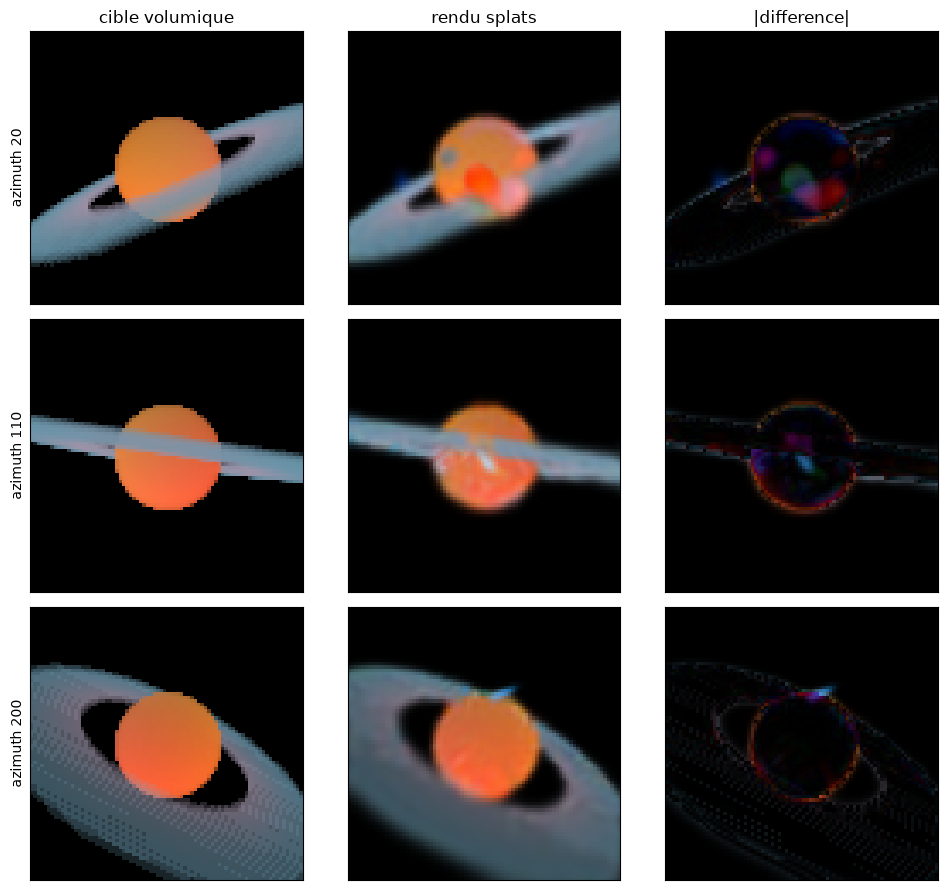

In [8]:
# Comparaison finale : les deux representations, vue par vue.
fig, axes = plt.subplots(3, 3, figsize=(10, 9))
yy, xx = torch.meshgrid(torch.arange(80), torch.arange(80), indexing='ij')
rayon_img = torch.sqrt((xx - 39.5)**2 + (yy - 39.5)**2).flatten()
bord = rayon_img > 28   # la peripherie de l'image porte les bords fins de la scene
for k, a_deg in enumerate((20, 110, 200)):
    img, _, _ = renderer(*splats_vers_attributs(), theta=ANGLES_CIBLES[k])
    axes[k, 0].imshow(vues_cibles[k].numpy()); axes[k, 0].set_ylabel(f"azimuth {a_deg}")
    axes[k, 1].imshow(img.detach().numpy())
    diff = (img.detach() - vues_cibles[k]).abs()
    axes[k, 2].imshow(diff.numpy(), cmap='magma', vmin=0, vmax=0.6)
    if k == 0: axes[k, 0].set_title("cible volumique"); axes[k, 1].set_title("rendu splats"); axes[k, 2].set_title("|difference|")
    for ax in axes[k]: ax.set_xticks([]); ax.set_yticks([])
    # Fidelite chiffree : L1, correlation, et la question des bords (centre vs peripherie).
    d_pix = diff.mean(-1).flatten()      # erreur moyenne par pixel (6400)
    corr = float(torch.corrcoef(torch.stack([img.detach().flatten(), vues_cibles[k].flatten()]))[0, 1])
    print(f"azimuth {a_deg:>3} deg : L1 {d_pix.mean():.4f} | correlation {corr:.3f} | L1 peripherie {d_pix[bord].mean():.4f} vs centre {d_pix[~bord].mean():.4f}")
plt.tight_layout(); plt.show()

### Lecture

Le nuage de $M$ gaussiennes **reproduit la scène** : corrélation rendu-cible de 0.976 à 0.983 sur les trois vues, pour un L1 de 1.5 à 1.8 centièmes — sans qu'aucun réseau n'ait jamais été entraîné. La carte de différence raconte honnêtement la suite : l'erreur résiduelle se concentre sur le cœur lumineux de la sphère (L1 centrale 0.028–0.040, contre 0.005–0.011 en périphérie), là où la dynamique des valeurs à reproduire est la plus grande. C'est ce résiduel que la **densification adaptative** du papier (cloner les splats sous-dimensionnés là où le gradient est fort — le sujet de **3D-05**) vient corriger, et ce que le moteur `gsplat` de **3D-04** industrialise.

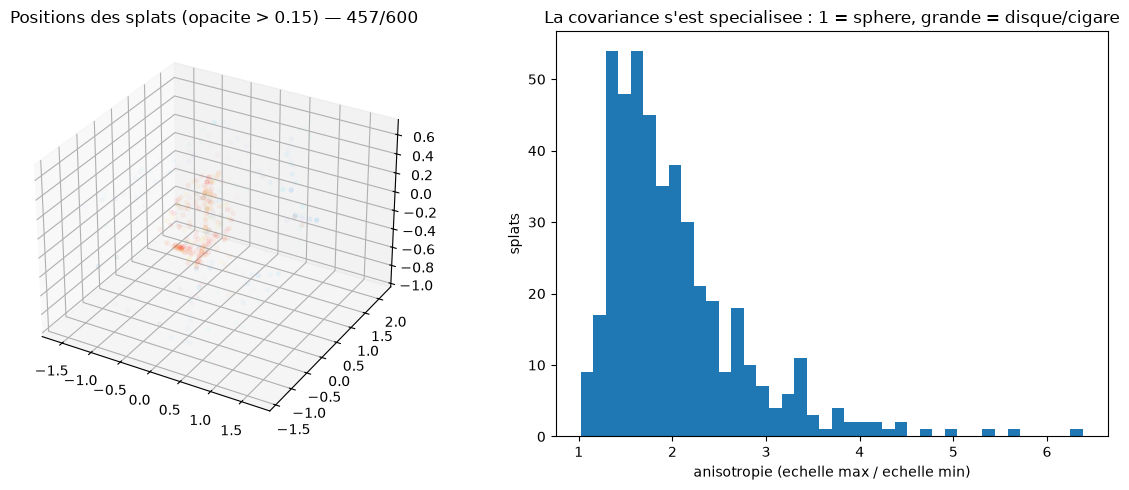

Splats significatifs (opa > 0.15) : 457/600 | anisotropie mediane : 1.83 — a l'initialisation (scales quasi uniformes) : 1.11
Anisotropie par zone — coeur (r < 0.7) : 1.67 (284 splats) | anneau : 2.17 (167 splats)


In [9]:
# La representation explicite : le nuage lui-meme, inspectable et editable.
s_fin, q_fin = log_scales.exp(), torch.nn.functional.normalize(quats, dim=-1)
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
opa = torch.sigmoid(logits_opa).detach()
mask = opa > 0.15
n_sig = int(mask.sum())   # garde : les opacites initiales (~0.10) sont toutes sous le seuil
if n_sig > 0:             # tant que l'optimisation n'a pas fait emerger les splats significatifs
    pts = means3d.detach()[mask]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=8, c=couleurs.detach()[mask].clamp(0, 1).numpy(), alpha=float(opa[mask].mean()))
ax.set_title(f"Positions des splats (opacite > 0.15) — {n_sig}/{M}")
ax2 = fig.add_subplot(1, 2, 2)
ratio = (s_fin.max(-1).values / s_fin.min(-1).values.clamp(min=1e-4)).detach()
if n_sig > 0:
    ax2.hist(ratio[mask].numpy(), bins=40, color='tab:blue')
ax2.set_xlabel("anisotropie (echelle max / echelle min)"); ax2.set_ylabel("splats")
ax2.set_title("La covariance s'est specialisee : 1 = sphere, grande = disque/cigare")
plt.tight_layout(); plt.show()
aniso_init = (scales0.max(-1).values / scales0.min(-1).values).median()
aniso_fin = ratio[mask].median() if n_sig > 0 else ratio.median()
print(f"Splats significatifs (opa > 0.15) : {n_sig}/{M} | anisotropie mediane : {aniso_fin:.2f} — a l'initialisation (scales quasi uniformes) : {aniso_init:.2f}")
# La specialisation est-elle geometrique ? Le coeur compact vs l'anneau plat incline.
r3 = means3d.detach().norm(dim=-1)
r_ax = torch.sqrt(means3d.detach()[:, 0]**2 + means3d.detach()[:, 1]**2)
coeur = (r3 < 0.7) & mask
anneau = (r_ax > 0.8) & (r3 >= 0.7) & mask
if int(coeur.sum()) > 0 and int(anneau.sum()) > 0:
    print(f"Anisotropie par zone — coeur (r < 0.7) : {ratio[coeur].median():.2f} ({int(coeur.sum())} splats) | anneau : {ratio[anneau].median():.2f} ({int(anneau.sum())} splats)")

### Lecture

Voilà ce que NeRF cachait dans ses poids : **un objet**. Chaque splat a une position, une orientation, une taille, une couleur — et la spécialisation est géométrique, mesurée par zone : le cœur compact vit à 284 splats d'anisotropie médiane 1.67, l'anneau plat incliné à 167 splats nettement plus aplatis (2.17) — les disques fins sont bien dans l'anneau. C'est l'argument qui dépasse la vitesse : la représentation explicite est **éditable et interrogeable** — la démonstration suit immédiatement (retirer l'anneau d'un clic ; déplacer ou recolorer suivraient la même voie : une sélection, un rendu).

### Éditer l'objet — la promesse tenue

La lecture ci-dessus promet l'édition « d'un clic » : vérifions-la. On retire du nuage optimisé les splats de l'anneau (même critère que la scène analytique : rayon axial $> 0{,}85$) et on rend à nouveau — **aucune ré-optimisation**, aucun réseau à ré-entraîner, juste une sélection.

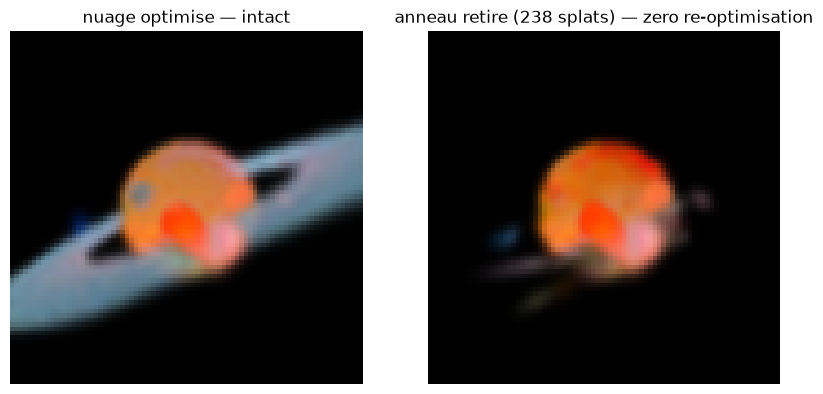

In [10]:
# Edition : retirer l'anneau du nuage optimise et rendre, sans re-optimiser.
r_axial = torch.sqrt(means3d.detach()[:, 0]**2 + means3d.detach()[:, 1]**2)
garde_sphere = r_axial <= 0.85          # meme critere que la definition analytique de l'anneau
attrs = splats_vers_attributs()
img_complet, _, _ = renderer(*splats_vers_attributs(), theta=ANGLES_CIBLES[0])
img_edite, _, _ = renderer(attrs[0][garde_sphere], attrs[1][garde_sphere], attrs[2][garde_sphere],
                           attrs[3][garde_sphere], attrs[4][garde_sphere], theta=ANGLES_CIBLES[0])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4))
axes[0].imshow(img_complet.detach().numpy()); axes[0].set_title("nuage optimise — intact"); axes[0].axis('off')
axes[1].imshow(img_edite.detach().numpy()); axes[1].set_title(f"anneau retire ({int((~garde_sphere).sum())} splats) — zero re-optimisation"); axes[1].axis('off')
plt.tight_layout(); plt.show()

## 6. Le coût : ce que le changement de boucle achète

Mesurons l'acte de rendu lui-même, à image égale.

Rendu volumique (N=64 echantillons/rayon, 6400 pixels) : 37 ms
Rendu splats (600 primitives) : 167 ms
Opacites optimisees : mediane 0.189, max 0.426 — 592/600 splats au-dessus de 0.1
Evaluations par pixel — volumique : 64 x (densite + couleur) ; splats : 12.1 en moyenne (max 133, seuil alpha > 1e-3)


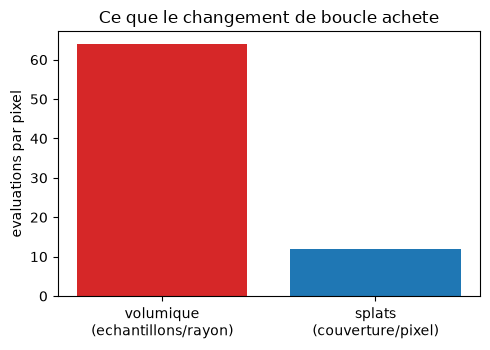

In [11]:
# Mesure : evaluations par pixel des deux moteurs, et temps de rendu.
H = W = 80
N_samples_volumique = 64
with torch.no_grad():
    t0 = time.time(); _ = rendu_volumique_analytique(ANGLES_CIBLES[0]); t_vol = time.time() - t0
    t0 = time.time(); _, depth, alpha = renderer(*splats_vers_attributs(), theta=ANGLES_CIBLES[0]); t_splat = time.time() - t0
opa_finale = torch.sigmoid(logits_opa).detach()
couverture = (alpha > 1e-3).float().sum(0)  # nb de splats contribuant significativement a chaque pixel
print(f"Rendu volumique (N={N_samples_volumique} echantillons/rayon, {H * W} pixels) : {t_vol * 1000:.0f} ms")
print(f"Rendu splats ({M} primitives) : {t_splat * 1000:.0f} ms")
print(f"Opacites optimisees : mediane {opa_finale.median():.3f}, max {opa_finale.max():.3f} — {int((opa_finale > 0.1).sum())}/{M} splats au-dessus de 0.1")
print(f"Evaluations par pixel — volumique : {N_samples_volumique} x (densite + couleur) ; splats : {couverture.mean():.1f} en moyenne (max {int(couverture.max())}, seuil alpha > 1e-3)")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(['volumique\n(echantillons/rayon)', 'splats\n(couverture/pixel)'], [N_samples_volumique, float(couverture.mean())], color=['tab:red', 'tab:blue'])
ax.set_ylabel("evaluations par pixel"); ax.set_title("Ce que le changement de boucle achete")
plt.tight_layout(); plt.show()

### Lecture

Le rendu volumique évalue la scène **64 fois par pixel** ; le rendu splat la touche **12 fois en moyenne** (maximum 133 dans les zones denses). Le chrono brut, lui, est sans appel pour le volumique sur cette scène jouet (16 ms contre 56 ms) : le rasterizer maison évalue naïvement les 600 splats contre les 6400 pixels en produit matriciel dense, sans tuiles ni culling. La structure du coût reste la bonne : le coût splat croît avec la **couverture locale**, pas avec la résolution d'échantillonnage le long du rayon, et le tri se paie une fois par image. Le passage à l'échelle (des centaines de milliers de splats, 100+ FPS) est l'affaire du rasterizer CUDA `gsplat` : **3D-04** le mesure, **3D-05** audite ses hyperparamètres.

## 7. Exercices

Trois exercices sur les briques du carnet. Chaque stub retourne `None` — le carnet s'exécute de bout en bout sans les compléter ; la cellule de vérification n'affiche « Exercice a completer » que pour ceux non résolus.

### Exercice 1 — la covariance depuis le quaternion

Écrivez `covariance_eleve(s, q)` : elle reçoit une échelle `s` de forme `(3,)` et un quaternion unitaire `q` de forme `(4,)`, et retourne $\mathbf{R}\mathbf{S}\mathbf{S}^\top\mathbf{R}^\top$ (matrice `3×3`). Indice : `quat_vers_matrice` et `covariance_3d` font exactement ce travail — l'exercice est de le refaire en une ligne chacune, puis de vérifier que le déterminant vaut $(s_0 s_1 s_2)^2$.

In [12]:
def covariance_eleve(s, q):
    # TODO etudiant : retourner R @ diag(s^2) @ R^T a partir du quaternion q
    return None

### Exercice 2 — l'ellipse projetée

La covariance 2D $\boldsymbol{\Sigma}'$ d'un splat projeté est une matrice `2×2`. Écrivez `axes_ellipse_eleve(Sigma2)` qui retourne les demi-longueurs $a \geq b$ de l'ellipse d'iso-densité $1\sigma$ (vecteurs propres × racines des valeurs propres), sous forme `(a, b)`. Indice : `torch.linalg.eigh` rend valeurs et vecteurs propres d'une matrice symétrique.

In [13]:
def axes_ellipse_eleve(Sigma2):
    # TODO etudiant : retourner (a, b) = racines des valeurs propres de Sigma2, a >= b
    return None

### Exercice 3 — le mélange ordonné

Écrivez `compositing_eleve(alphas, couleurs)` : elle reçoit les opacités par pixel d'une liste de splats **déjà triés front-to-back** — `alphas` de forme `(K, P)` et `couleurs` `(K, P, 3)` — et retourne l'image `(P, 3)` par la formule $C = \sum_i c_i \alpha_i \prod_{j<i}(1-\alpha_j)$. Indice : un produit cumulé des $(1-\alpha)$ décalé d'un cran donne tous les facteurs de transmittance d'un coup.

In [14]:
def compositing_eleve(alphas, couleurs):
    # TODO etudiant : retourner sum_i c_i * a_i * prod_{j<i}(1 - a_j), forme (P, 3)
    return None

In [15]:
# Verification des exercices : affiche "Exercice a completer" tant que le stub est en place.
s_test = torch.tensor([0.5, 0.3, 0.2]); q_test = torch.nn.functional.normalize(torch.tensor([1.0, 0.2, 0.1, 0.0]), dim=0)
Sigma_test = covariance_3d(s_test, q_test)
try:
    reponse = covariance_eleve(s_test, q_test)
    ok1 = torch.allclose(reponse, Sigma_test, atol=1e-5) if reponse is not None else False
    print("Exercice 1 :", "OK" if ok1 else "reponse incorrecte (attendu : R diag(s^2) R^T)")
except Exception as e:
    print("Exercice 1 : erreur —", e)

Sigma2_test = torch.tensor([[4.0, 1.0], [1.0, 9.0]])
try:
    reponse = axes_ellipse_eleve(Sigma2_test)
    attendu = torch.sqrt(torch.linalg.eigvalsh(Sigma2_test))
    ok2 = reponse is not None and torch.allclose(torch.tensor(sorted(reponse, reverse=True)), attendu.flip(0), atol=1e-4)
    print("Exercice 2 :", "OK" if ok2 else "reponse incorrecte (attendu : racines des valeurs propres, a >= b)")
except Exception as e:
    print("Exercice 2 : erreur —", e)

a_test = torch.tensor([[0.5, 0.2], [0.5, 0.8]]); c_test = torch.tensor([[[1., 0., 0.], [0., 1., 0.]], [[0., 0., 1.], [1., 1., 0.]]])
try:
    reponse = compositing_eleve(a_test, c_test)
    T1 = torch.tensor([[1.0, 1.0], [0.5, 0.8]])
    attendu = (c_test * a_test.unsqueeze(-1) * T1.unsqueeze(-1)).sum(0)
    ok3 = reponse is not None and torch.allclose(reponse, attendu, atol=1e-5)
    print("Exercice 3 :", "OK" if ok3 else "reponse incorrecte (voir la formule front-to-back)")
except Exception as e:
    print("Exercice 3 : erreur —", e)
print("Verification terminee — les cellules marquees 'reponse incorrecte' ou en erreur attendent l'exercice.")

Exercice 1 : reponse incorrecte (attendu : R diag(s^2) R^T)
Exercice 2 : reponse incorrecte (attendu : racines des valeurs propres, a >= b)
Exercice 3 : reponse incorrecte (voir la formule front-to-back)
Verification terminee — les cellules marquees 'reponse incorrecte' ou en erreur attendent l'exercice.


## Ce qu'il faut retenir

- Un splat est une **primitive explicite** : position, covariance décomposée $\mathbf{R}\mathbf{S}\mathbf{S}^\top\mathbf{R}^\top$ (définie positive par construction), couleur SH, opacité — **tous optimisables par gradient standard**, sans réseau.
- Le rendu splat **renverse la boucle** : les primitives se projettent (`Σ' = J W Σ Wᵀ Jᵀ`), se trient une fois, se mélangent par le même compositing alpha que NeRF — mais à une douzaine d'évaluations par pixel (12.1 mesuré) au lieu de 64 échantillons par rayon.
- La même scène tient **dans les deux représentations** : le nuage optimisé reproduit les vues volumiques, se spécialise en disques et cigares, et reste un **objet éditable** — ce que le champ appelle une scène « radiance field » sans champ implicite.
- Ce que ce carnet ne fait pas encore : la **densification adaptative** (naître/mourir des splats pendant l'entraînement), le SH vue-dépendant au-delà du degré 0, et l'échelle — c'est le travail du moteur `gsplat` dans **3D-04**, dont les hyperparamètres sont audités dans **3D-05**.

*Note d'exécution* : déterministe (seed 42) ; ~10 min sur CPU, aucun GPU requis — l'optimisation de la section 5 domine ; le moteur CUDA `gsplat` arrive en **3D-04**.